# CICIoT2023 NoFeature-Augmented LSTM — Five-Seed Final Evaluation

## 1. Environment and reproducibility


In [1]:
# Global reproducibility setup
import os
import random
import numpy as np
import tensorflow as tf

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
print("Global seed set to:", SEED)


Global seed set to: 42


In [2]:
import pandas as pd
import numpy as np
import sklearn, os
from sklearn.preprocessing import StandardScaler # RobustScaler
import matplotlib.pyplot as plt  # for plotting
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, confusion_matrix
from sklearn.metrics import roc_auc_score, roc_curve, auc
from tensorflow.keras.optimizers import Adam

from sklearn.preprocessing import LabelEncoder
import seaborn as sns 
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report
import time


## 2. Load preprocessed and feature-augmented data

### Directly clean Augmented data 


In [3]:
# ============================================================
# Load the augmented partitions
train_data = pd.read_csv(
    r"/kaggle/input/datasets/zerukifle/ciciot2023-fa-multirun/CICIoT2023_Augmented_Train.csv"
)

validation_data = pd.read_csv(
    r"/kaggle/input/datasets/zerukifle/ciciot2023-fa-multirun/CICIoT2023_Augmented_Validation.csv"
)

test_data = pd.read_csv(
    r"/kaggle/input/datasets/zerukifle/ciciot2023-fa-multirun/CICIoT2023_Augmented_Test.csv"
)


print(f"Training data:   {train_data.shape}")
print(f"Validation data: {validation_data.shape}")
print(f"Test data:       {test_data.shape}")

display(train_data.head())


Training data:   (354737, 36)
Validation data: (118246, 36)
Test data:       (118246, 36)


,flow_duration,Header_Length,Protocol Type,Duration,Rate,Drate,fin_flag_number,syn_flag_number,psh_flag_number,ack_flag_number,...,Max,AVG,Tot size,IAT,Covariance,Variance,IF_Anomaly_Score,AE_Anomaly_Score,SUOD_Anomaly_Score,label
0,0.244612,38791.0,17.00,64.00,3202.228500,0.0,0.0,0.0,0.0,0.0,...,50.00,50.00000,50.00,83102420.0,0.000000,0.00,0.275168,0.004453,-0.277339,DDoS
1,0.014093,5675.0,17.00,64.00,8785.439000,0.0,0.0,0.0,0.0,0.0,...,50.00,50.00000,50.00,83123740.0,0.000000,0.00,0.283322,0.004197,-0.291433,DDoS
2,0.000000,0.0,47.00,64.00,218.863710,0.0,0.0,0.0,0.0,0.0,...,592.00,592.00000,592.00,83698550.0,0.000000,0.00,0.161012,0.083652,0.648249,Mirai
3,0.000000,54.0,6.00,64.00,3.887012,0.0,0.0,0.0,0.0,0.0,...,54.00,54.00000,54.00,83064136.0,0.000000,0.00,0.319291,0.000523,-0.766263,DDoS
4,0.000000,0.0,0.99,63.36,5.231067,0.0,0.0,0.0,0.0,0.0,...,43.98,42.13838,42.18,83150650.0,2.315749,0.11,0.216951,0.004651,0.238320,DDoS


In [4]:
# ============================================================
# Dataset validation + feature-ablation configuration
# ============================================================

# Target column used throughout the notebook.
LABEL_COLUMN = "label"

# Anomaly-score features used by ODLID feature augmentation.
ANOMALY_FEATURES = [
    "IF_Anomaly_Score",
    "AE_Anomaly_Score",
    "SUOD_Anomaly_Score",
]

# ============================================================
# Select the experiment mode
# ============================================================
# Change ONLY this line when running another configuration.
#
# "Full_FA"   -> original features + IF + AE + SUOD
# "No_FA"     -> original traffic features only
# "IF_only"   -> original features + IF only
# "AE_only"   -> original features + AE only
# "SUOD_only" -> original features + SUOD only

ABLATION_MODE = "No_FA"

# ============================================================
# Validate the originally loaded augmented partitions
# ============================================================
# Every experiment starts from the same augmented train,
# validation, and test partitions. Only selected anomaly-score
# columns are removed; samples, labels, and split membership
# remain unchanged.

for dataset_name, dataset in {
    "Training": train_data,
    "Validation": validation_data,
    "Test": test_data,
}.items():

    if LABEL_COLUMN not in dataset.columns:
        raise KeyError(
            f"'{LABEL_COLUMN}' was not found in the "
            f"{dataset_name} dataset."
        )

    missing_anomaly_features = [
        feature
        for feature in ANOMALY_FEATURES
        if feature not in dataset.columns
    ]

    if missing_anomaly_features:
        raise KeyError(
            f"{dataset_name} dataset is missing "
            f"the following anomaly-score features: "
            f"{missing_anomaly_features}"
        )

# ============================================================
# Determine which anomaly-score features should be removed
# ============================================================

if ABLATION_MODE == "Full_FA":
    features_to_drop = []

elif ABLATION_MODE == "No_FA":
    features_to_drop = [
        "IF_Anomaly_Score",
        "AE_Anomaly_Score",
        "SUOD_Anomaly_Score",
    ]

elif ABLATION_MODE == "IF_only":
    features_to_drop = [
        "AE_Anomaly_Score",
        "SUOD_Anomaly_Score",
    ]

elif ABLATION_MODE == "AE_only":
    features_to_drop = [
        "IF_Anomaly_Score",
        "SUOD_Anomaly_Score",
    ]

elif ABLATION_MODE == "SUOD_only":
    features_to_drop = [
        "IF_Anomaly_Score",
        "AE_Anomaly_Score",
    ]

else:
    raise ValueError(
        f"Unknown ABLATION_MODE: {ABLATION_MODE}. "
        "Use Full_FA, No_FA, IF_only, AE_only, or SUOD_only."
    )

# ============================================================
# Apply the selected feature ablation
# ============================================================

train_data = train_data.drop(
    columns=features_to_drop
).copy()

validation_data = validation_data.drop(
    columns=features_to_drop
).copy()

test_data = test_data.drop(
    columns=features_to_drop
).copy()

# Rebuild the ordered feature list AFTER ablation.
feature_columns = [
    column
    for column in train_data.columns
    if column != LABEL_COLUMN
]

# Confirm identical feature order in every partition.
validation_feature_columns = [
    column
    for column in validation_data.columns
    if column != LABEL_COLUMN
]

test_feature_columns = [
    column
    for column in test_data.columns
    if column != LABEL_COLUMN
]

if feature_columns != validation_feature_columns:
    raise ValueError(
        "Training and validation feature columns do not match "
        "after applying the ablation configuration."
    )

if feature_columns != test_feature_columns:
    raise ValueError(
        "Training and test feature columns do not match "
        "after applying the ablation configuration."
    )

kept_anomaly_features = [
    feature
    for feature in ANOMALY_FEATURES
    if feature in feature_columns
]

print("=" * 60)
print("Feature-ablation configuration")
print("=" * 60)
print(f"Ablation mode: {ABLATION_MODE}")
print(f"Number of input features: {len(feature_columns)}")
print(f"Kept anomaly-score features: {kept_anomaly_features}")
print(f"Dropped anomaly-score features: {features_to_drop}")
print(f"Training instances: {len(train_data):,}")
print(f"Validation instances: {len(validation_data):,}")
print(f"Test instances: {len(test_data):,}")
print("=" * 60)


Feature-ablation configuration
Ablation mode: No_FA
Number of input features: 32
Kept anomaly-score features: []
Dropped anomaly-score features: ['IF_Anomaly_Score', 'AE_Anomaly_Score', 'SUOD_Anomaly_Score']
Training instances: 354,737
Validation instances: 118,246
Test instances: 118,246


### Separate augmented features and multiclass labels


In [5]:
# import numpy as np

# from sklearn.preprocessing import LabelEncoder


# ============================================================
# Extract augmented feature matrices
# ============================================================
# feature_columns were defined in the validation cell.
# Selecting these columns preserves the training column order.
X_train = train_data[
    feature_columns
].copy()

X_val = validation_data[
    feature_columns
].copy()

X_test = test_data[
    feature_columns
].copy()


# ============================================================
# Validate numeric feature values
# ============================================================
for dataset_name, feature_data in {
    "Training": X_train,
    "Validation": X_val,
    "Test": X_test
}.items():

    non_numeric_columns = feature_data.select_dtypes(
        exclude=np.number
    ).columns.tolist()

    if non_numeric_columns:
        raise TypeError(
            f"{dataset_name} data contain non-numeric "
            f"features: {non_numeric_columns}"
        )

    if not np.isfinite(
        feature_data.to_numpy(dtype=np.float32)
    ).all():
        raise ValueError(
            f"{dataset_name} features contain missing "
            "or infinite values."
        )


# ============================================================
# Extract original multiclass labels
# ============================================================
y_train_original = (
    train_data[LABEL_COLUMN]
    .astype(str)
    .str.strip()
)

y_val_original = (
    validation_data[LABEL_COLUMN]
    .astype(str)
    .str.strip()
)

y_test_original = (
    test_data[LABEL_COLUMN]
    .astype(str)
    .str.strip()
)


print(f"Training features:   {X_train.shape}")
print(f"Validation features: {X_val.shape}")
print(f"Test features:       {X_test.shape}")

print(
    f"\nNumber of training classes: "
    f"{y_train_original.nunique()}"
)

display(y_train_original.value_counts())


Training features:   (354737, 32)
Validation features: (118246, 32)
Test features:       (118246, 32)

Number of training classes: 8


label
DDoS          258100
DoS            61405
Mirai          20231
Benign          8248
Spoofing        3729
Recon           2736
Web              188
BruteForce       100
Name: count, dtype: int64

#### Encode the multiclass labels


In [6]:
# ============================================================
# Fit the label encoder on training labels only
# ============================================================
label_encoder = LabelEncoder()

y_train = label_encoder.fit_transform(
    y_train_original
)


# ============================================================
# Check for unknown validation or test classes
# ============================================================
training_classes = set(
    label_encoder.classes_
)

unknown_validation_classes = (
    set(y_val_original.unique())
    - training_classes
)

unknown_test_classes = (
    set(y_test_original.unique())
    - training_classes
)

if unknown_validation_classes:
    raise ValueError(
        "Validation data contain classes that are absent "
        f"from training: {sorted(unknown_validation_classes)}"
    )

if unknown_test_classes:
    raise ValueError(
        "Test data contain classes that are absent "
        f"from training: {sorted(unknown_test_classes)}"
    )


# Transform validation and test labels using the same encoder
y_val = label_encoder.transform(
    y_val_original
)

y_test = label_encoder.transform(
    y_test_original
)


# ============================================================
# Display multiclass mapping
# ============================================================
print("Multiclass label mapping:")

for class_code, class_name in enumerate(
    label_encoder.classes_
):
    print(f"{class_code}: {class_name}")


number_of_classes = len(
    label_encoder.classes_
)

print(
    f"\nNumber of multiclass target classes: "
    f"{number_of_classes}"
)


Multiclass label mapping:
0: Benign
1: BruteForce
2: DDoS
3: DoS
4: Mirai
5: Recon
6: Spoofing
7: Web

Number of multiclass target classes: 8


#### Standardize the augmented features


In [7]:
from sklearn.preprocessing import StandardScaler


# ============================================================
# Fit the scaler on augmented training features only
# ============================================================
classifier_scaler = StandardScaler()

X_train_scaled = classifier_scaler.fit_transform(
    X_train
).astype(np.float32)


# Apply the same fitted scaler without refitting
X_val_scaled = classifier_scaler.transform(
    X_val
).astype(np.float32)

X_test_scaled = classifier_scaler.transform(
    X_test
).astype(np.float32)


# ============================================================
# Verify scaled data
# ============================================================
if not np.isfinite(X_train_scaled).all():
    raise ValueError(
        "Scaled training features contain invalid values."
    )

if not np.isfinite(X_val_scaled).all():
    raise ValueError(
        "Scaled validation features contain invalid values."
    )

if not np.isfinite(X_test_scaled).all():
    raise ValueError(
        "Scaled test features contain invalid values."
    )


print(f"Scaled training features:   {X_train_scaled.shape}")
print(f"Scaled validation features: {X_val_scaled.shape}")
print(f"Scaled test features:       {X_test_scaled.shape}")

print(
    f"\nTraining mean after scaling: "
    f"{X_train_scaled.mean():.6f}"
)

print(
    f"Training standard deviation after scaling: "
    f"{X_train_scaled.std():.6f}"
)


Scaled training features:   (354737, 32)
Scaled validation features: (118246, 32)
Scaled test features:       (118246, 32)

Training mean after scaling: 0.000000
Training standard deviation after scaling: 1.000000


## 3. Long Short-Term Memory Network (LSTM)


In [8]:
# Preserve the original one-time-step representation, using scaled inputs.
input_attribute_count = X_train_scaled.shape[1]

X_train_reshaped_lstm = X_train_scaled.reshape(
    -1, 1, input_attribute_count
)
X_val_reshaped_lstm = X_val_scaled.reshape(
    -1, 1, input_attribute_count
)
X_test_reshaped_lstm = X_test_scaled.reshape(
    -1, 1, input_attribute_count
)

print(f"LSTM training shape:   {X_train_reshaped_lstm.shape}")
print(f"LSTM validation shape: {X_val_reshaped_lstm.shape}")
print(f"LSTM test shape:       {X_test_reshaped_lstm.shape}")


LSTM training shape:   (354737, 1, 32)
LSTM validation shape: (118246, 1, 32)
LSTM test shape:       (118246, 1, 32)


### Optional LSTM hyperparameter optimization

The original LSTM Optuna structure is retained for future use.

- Keep `RUN_OPTUNA = False` for the current 5-seed final experiment.
  The previously stored optimized LSTM parameters are loaded.
- Change `RUN_OPTUNA = True` only when you want to perform a new
  hyperparameter search.

The optimization uses the training and validation partitions only.
The test partition is not used for hyperparameter selection.


In [9]:
# ============================================================
# LSTM optimization control
# ============================================================

import json
import os

# False -> use the previously stored optimized parameters.
# True  -> run a new Optuna search and save the new parameters.
RUN_OPTUNA = False

N_OPTUNA_TRIALS = 25


# ------------------------------------------------------------
# Existing optimized parameter file.
# Kaggle input directories are read-only.
# ------------------------------------------------------------
PRESTORED_PARAMS_LSTM_FILE = (
    "/kaggle/input/datasets/zerukifle/ciciot2023-fa-multirun/best_params_lstm_imbalanceCICIoT2023.json"
)


# ------------------------------------------------------------
# Newly optimized parameter file.
# Kaggle working directory is writable.
# ------------------------------------------------------------
NEW_PARAMS_LSTM_FILE = (
    "/kaggle/working/"
    "best_params_lstm_imbalanceCICIoT2023.json"
)


print(
    "RUN_OPTUNA:",
    RUN_OPTUNA,
)

print(
    "Number of Optuna trials:",
    N_OPTUNA_TRIALS,
)

if RUN_OPTUNA:
    print(
        "New optimized LSTM parameters will be saved to:",
        NEW_PARAMS_LSTM_FILE,
    )
else:
    print(
        "Pre-stored LSTM parameters will be loaded from:",
        PRESTORED_PARAMS_LSTM_FILE,
    )


RUN_OPTUNA: False
Number of Optuna trials: 25
Pre-stored LSTM parameters will be loaded from: /kaggle/input/datasets/zerukifle/ciciot2023-fa-multirun/best_params_lstm_imbalanceCICIoT2023.json


In [10]:
from sklearn.metrics import f1_score
from tensorflow.keras.layers import (
    LSTM,
    Dense,
    Dropout,
    Input,
)
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2


class SparseMacroF1(tf.keras.metrics.Metric):
    """Dataset-level macro F1 for sparse integer multiclass labels."""

    def __init__(
        self,
        number_of_classes,
        name="macro_f1",
        **kwargs,
    ):
        super().__init__(
            name=name,
            **kwargs,
        )

        self.number_of_classes = int(
            number_of_classes
        )

        self.confusion_matrix = self.add_weight(
            name="confusion_matrix",
            shape=(
                self.number_of_classes,
                self.number_of_classes,
            ),
            initializer="zeros",
            dtype=tf.float32,
        )

    def update_state(
        self,
        y_true,
        y_pred,
        sample_weight=None,
    ):
        y_true = tf.cast(
            tf.reshape(
                y_true,
                [-1],
            ),
            tf.int32,
        )

        y_pred = tf.argmax(
            y_pred,
            axis=1,
            output_type=tf.int32,
        )

        weights = None

        if sample_weight is not None:
            weights = tf.cast(
                tf.reshape(
                    sample_weight,
                    [-1],
                ),
                tf.float32,
            )

        batch_confusion_matrix = (
            tf.math.confusion_matrix(
                y_true,
                y_pred,
                num_classes=(
                    self.number_of_classes
                ),
                weights=weights,
                dtype=tf.float32,
            )
        )

        self.confusion_matrix.assign_add(
            batch_confusion_matrix
        )

    def result(self):
        true_positives = (
            tf.linalg.diag_part(
                self.confusion_matrix
            )
        )

        false_positives = (
            tf.reduce_sum(
                self.confusion_matrix,
                axis=0,
            )
            - true_positives
        )

        false_negatives = (
            tf.reduce_sum(
                self.confusion_matrix,
                axis=1,
            )
            - true_positives
        )

        class_f1 = tf.math.divide_no_nan(
            2.0 * true_positives,
            2.0 * true_positives
            + false_positives
            + false_negatives,
        )

        return tf.reduce_mean(
            class_f1
        )

    def reset_state(self):
        self.confusion_matrix.assign(
            tf.zeros_like(
                self.confusion_matrix
            )
        )

    def get_config(self):
        config = super().get_config()

        config.update(
            {
                "number_of_classes":
                    self.number_of_classes
            }
        )

        return config


In [11]:
# ============================================================
# Recommended LSTM Optuna objective and search space
# ============================================================

# Fixed maximum number of epochs for every Optuna trial and
# every final seed run. Early stopping determines the effective
# number of epochs independently for each training run.
MAX_EPOCHS_LSTM = 100

# Keep the same early-stopping rule during optimization and
# final five-seed training.
EARLY_STOPPING_PATIENCE = 10


def objective_lstm(trial):
    """Train one LSTM trial and return validation macro F1."""

    tf.keras.backend.clear_session()

    tf.keras.utils.set_random_seed(
        SEED + trial.number
    )

    # --------------------------------------------------------
    # Architecture-specific recurrent-unit search space
    # --------------------------------------------------------
    hidden_layer1_lstm = trial.suggest_int(
        "hidden_layer1_lstm",
        32,
        128,
        step=16,
    )

    hidden_layer2_lstm = trial.suggest_int(
        "hidden_layer2_lstm",
        16,
        64,
        step=16,
    )

    # --------------------------------------------------------
    # Shared optimization search space
    # --------------------------------------------------------
    dropout_rate_lstm = trial.suggest_float(
        "dropout_rate_lstm",
        0.1,
        0.4,
        step=0.1,
    )

    l2_reg_lstm = trial.suggest_float(
        "l2_reg_lstm",
        1e-6,
        1e-3,
        log=True,
    )

    batch_size_lstm = trial.suggest_categorical(
        "batch_size_lstm",
        [64, 128, 256],
    )

    learning_rate_lstm = trial.suggest_float(
        "learning_rate_lstm",
        1e-5,
        1e-2,
        log=True,
    )

    model_lstm_trial = Sequential(
        [
            Input(
                shape=(
                    1,
                    input_attribute_count,
                )
            ),

            LSTM(
                hidden_layer1_lstm,
                return_sequences=True,
                kernel_regularizer=l2(
                    l2_reg_lstm
                ),
            ),

            Dropout(
                dropout_rate_lstm
            ),

            LSTM(
                hidden_layer2_lstm,
                return_sequences=False,
                kernel_regularizer=l2(
                    l2_reg_lstm
                ),
            ),

            Dropout(
                dropout_rate_lstm
            ),

            Dense(
                number_of_classes,
                activation="softmax",
                kernel_regularizer=l2(
                    l2_reg_lstm
                ),
            ),
        ],
        name="LSTM_Optuna_Trial",
    )

    model_lstm_trial.compile(
        loss="sparse_categorical_crossentropy",

        optimizer=Adam(
            learning_rate=(
                learning_rate_lstm
            )
        ),

        metrics=[
            "accuracy",

            SparseMacroF1(
                number_of_classes
            ),
        ],
    )

    # --------------------------------------------------------
    # Fixed maximum epochs + validation-based early stopping
    # --------------------------------------------------------
    model_lstm_trial.fit(
        X_train_reshaped_lstm,
        y_train,

        epochs=MAX_EPOCHS_LSTM,

        batch_size=batch_size_lstm,

        validation_data=(
            X_val_reshaped_lstm,
            y_val,
        ),

        callbacks=[
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=EARLY_STOPPING_PATIENCE,
                restore_best_weights=True,
            ),

            KerasPruningCallback(
                trial,
                monitor="val_macro_f1",
                interval=1,
            ),
        ],

        shuffle=True,
        verbose=0,
    )

    validation_probabilities = (
        model_lstm_trial.predict(
            X_val_reshaped_lstm,
            verbose=0,
        )
    )

    validation_predictions = np.argmax(
        validation_probabilities,
        axis=1,
    )

    validation_macro_f1 = f1_score(
        y_val,
        validation_predictions,

        labels=np.arange(
            number_of_classes
        ),

        average="macro",
        zero_division=0,
    )

    del model_lstm_trial

    tf.keras.backend.clear_session()

    return float(
        validation_macro_f1
    )


In [13]:
# !pip install optuna-integration[keras]

In [14]:
# ============================================================
# Execute optional LSTM Optuna optimization
# ============================================================

if RUN_OPTUNA:

    import optuna
    from optuna.trial import TrialState

    try:
        from optuna_integration import (
            KerasPruningCallback
        )
    except ImportError:
        from optuna.integration import (
            KerasPruningCallback
        )

    # TPE sampling and median-based early pruning.
    study_lstm = optuna.create_study(
        direction="maximize",
        sampler=(
            optuna.samplers.TPESampler(
                seed=SEED
            )
        ),
        pruner=(
            optuna.pruners.MedianPruner(
                n_startup_trials=5,
                n_warmup_steps=10,
                interval_steps=1,
            )
        ),
    )

    study_lstm.optimize(
        objective_lstm,
        n_trials=N_OPTUNA_TRIALS,
        n_jobs=1,
        gc_after_trial=True,
    )

    complete_trials_lstm = (
        study_lstm.get_trials(
            deepcopy=False,
            states=[
                TrialState.COMPLETE
            ],
        )
    )

    pruned_trials_lstm = (
        study_lstm.get_trials(
            deepcopy=False,
            states=[
                TrialState.PRUNED
            ],
        )
    )

    failed_trials_lstm = (
        study_lstm.get_trials(
            deepcopy=False,
            states=[
                TrialState.FAIL
            ],
        )
    )

    print(
        "Best LSTM hyperparameters:",
        study_lstm.best_params,
    )

    print(
        "Best LSTM validation macro F1: "
        f"{study_lstm.best_value:.6f}"
    )

    print(
        "LSTM study statistics:"
    )

    print(
        "  Number of finished trials:",
        len(
            study_lstm.trials
        ),
    )

    print(
        "  Number of complete trials:",
        len(
            complete_trials_lstm
        ),
    )

    print(
        "  Number of pruned trials:",
        len(
            pruned_trials_lstm
        ),
    )

    print(
        "  Number of failed trials:",
        len(
            failed_trials_lstm
        ),
    )

    best_trial_lstm = (
        study_lstm.best_trial
    )

    print(
        "  Best validation macro F1: "
        f"{best_trial_lstm.value:.6f}"
    )

    print(
        "  Best parameters:"
    )

    for (
        key,
        value,
    ) in best_trial_lstm.params.items():
        print(
            f"    {key}: {value}"
        )

    # Preserve the original parameter variable name.
    best_params_lstm_imbalaceCICIoT2023 = (
        study_lstm.best_params
    )

    with open(
        NEW_PARAMS_LSTM_FILE,
        "w",
        encoding="utf-8",
    ) as json_file:
        json.dump(
            best_params_lstm_imbalaceCICIoT2023,
            json_file,
            indent=2,
        )

    print(
        "New optimized LSTM parameters saved to:",
        NEW_PARAMS_LSTM_FILE,
    )

else:
    print(
        "Optuna optimization skipped. "
        "Using the pre-stored LSTM parameters."
    )


Optuna optimization skipped. Using the pre-stored LSTM parameters.


### Load the optimized LSTM parameters for final training

This cell is always executed.

- With `RUN_OPTUNA = False`, it loads the existing pre-stored JSON.
- With `RUN_OPTUNA = True`, it loads the newly optimized JSON saved above.

The original final-training variable name `best_params_lstm_imbalaceCICIoT2023` is retained.


In [15]:
import json

# ============================================================
# Select the LSTM parameter file used by final training
# ============================================================

if RUN_OPTUNA:
    PARAMS_LSTM_FILE_TO_LOAD = (
        NEW_PARAMS_LSTM_FILE
    )
else:
    PARAMS_LSTM_FILE_TO_LOAD = (
        PRESTORED_PARAMS_LSTM_FILE
    )


if not os.path.exists(
    PARAMS_LSTM_FILE_TO_LOAD
):
    raise FileNotFoundError(
        "LSTM parameter file not found: "
        f"{PARAMS_LSTM_FILE_TO_LOAD}"
    )


# Load the optimized parameters used by final LSTM training.
with open(
    PARAMS_LSTM_FILE_TO_LOAD,
    "r",
    encoding="utf-8",
) as json_file:
    best_params_lstm_imbalaceCICIoT2023 = json.load(
        json_file
    )


print(
    "LSTM parameters loaded for final training from:"
)

print(
    PARAMS_LSTM_FILE_TO_LOAD
)

best_params_lstm_imbalaceCICIoT2023


LSTM parameters loaded for final training from:
/kaggle/input/datasets/zerukifle/ciciot2023-fa-multirun/best_params_lstm_imbalanceCICIoT2023.json


{'hidden_layer1_lstm': 128,
 'hidden_layer2_lstm': 32,
 'dropout_rate_lstm': 0.2,
 'l2_reg_lstm': 1.1321021804230381e-06,
 'batch_size_lstm': 64,
 'learning_rate_lstm': 0.0011769044926591633}

## 4. Five-run final training

In [16]:
from pathlib import Path
import gc
import joblib

from tensorflow.keras import regularizers
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import (
    matthews_corrcoef,
    multilabel_confusion_matrix,
    precision_recall_fscore_support,
    roc_auc_score,
)


# ============================================================
# Repeated-run protocol
# ============================================================
RUN_SEEDS = [42, 43, 44, 45, 46]
N_FINAL_RUNS = len(RUN_SEEDS)

N_WARMUP_RUNS = 3
# Five timed full-test inference repetitions per trained model.
N_BENCHMARK_RUNS = 5

REPORT_OUTPUT_DIRECTORY = (
    Path.cwd()
    / f"CICIoT2023_Imbalance_LSTM_{ABLATION_MODE}_5_seed"
)

# Keep the original variable name for compatibility.
# Each LSTM_Seed_* folder is created directly inside this directory.
MODEL_OUTPUT_DIRECTORY = REPORT_OUTPUT_DIRECTORY

REPORT_OUTPUT_DIRECTORY.mkdir(
    parents=True,
    exist_ok=True,
)


# ============================================================
# ADDED FOR REPRODUCIBILITY
# Save the preprocessing objects and exact test inputs needed
# to regenerate predictions and benchmark the saved pretrained
# LSTM models later without refitting preprocessing.
# ============================================================

# Save the StandardScaler fitted on the training partition only.
joblib.dump(
    classifier_scaler,
    REPORT_OUTPUT_DIRECTORY
    / "classifier_scaler.joblib",
)

# Save the exact ordered classifier feature list.
with open(
    REPORT_OUTPUT_DIRECTORY
    / "feature_columns.json",
    "w",
    encoding="utf-8",
) as json_file:
    json.dump(
        list(feature_columns),
        json_file,
        indent=2,
    )

# Save the class-name ordering used by the label encoder.
with open(
    REPORT_OUTPUT_DIRECTORY
    / "class_names.json",
    "w",
    encoding="utf-8",
) as json_file:
    json.dump(
        label_encoder.classes_.tolist(),
        json_file,
        indent=2,
    )

# Save the exact scaled 2-D test matrix.
np.save(
    REPORT_OUTPUT_DIRECTORY
    / "X_test_scaled.npy",
    X_test_scaled,
)

# Save the exact reshaped test tensor provided to the LSTM.
# This is the preferred input for later inference benchmarking.
np.save(
    REPORT_OUTPUT_DIRECTORY
    / "X_test_reshaped_lstm.npy",
    X_test_reshaped_lstm,
)

# Save the exact tensor under a generic name for standalone
# offline inference benchmarking.
np.save(
    REPORT_OUTPUT_DIRECTORY
    / "X_test_model_input.npy",
    X_test_reshaped_lstm,
)

# Save the exact encoded test labels for metric regeneration.
np.save(
    REPORT_OUTPUT_DIRECTORY
    / "y_test.npy",
    y_test,
)

# Save the selected LSTM hyperparameters together with the
# experiment outputs so the result folder is self-contained.
with open(
    REPORT_OUTPUT_DIRECTORY
    / "best_params_lstm_imbalanceCIC2023.json",
    "w",
    encoding="utf-8",
) as json_file:
    json.dump(
        best_params_lstm_imbalaceCICIoT2023,
        json_file,
        indent=2,
    )

with open(
    REPORT_OUTPUT_DIRECTORY
    / "selected_hyperparameters.json",
    "w",
    encoding="utf-8",
) as json_file:
    json.dump(
        best_params_lstm_imbalaceCICIoT2023,
        json_file,
        indent=2,
    )



# Save software/hardware metadata used for reproducibility.
import platform

environment_metadata = {
    "Python": platform.python_version(),
    "TensorFlow": tf.__version__,
    "NumPy": np.__version__,
    "Pandas": pd.__version__,
    "Scikit_learn": sklearn.__version__,
    "Platform": platform.platform(),
    "Machine": platform.machine(),
    "Processor": platform.processor(),
    "TensorFlow_Visible_Devices": [
        str(device)
        for device in tf.config.get_visible_devices()
    ],
    "Ablation_Mode": ABLATION_MODE,
    "Kept_Anomaly_Features": kept_anomaly_features,
    "Dropped_Anomaly_Features": features_to_drop,
    "Final_Seeds": RUN_SEEDS,
    "Inference_Warmup_Runs": N_WARMUP_RUNS,
    "Inference_Timed_Runs": N_BENCHMARK_RUNS,
}

with open(
    REPORT_OUTPUT_DIRECTORY / "environment_metadata.json",
    "w",
    encoding="utf-8",
) as json_file:
    json.dump(
        environment_metadata,
        json_file,
        indent=2,
    )

print(
    "Saved global LSTM reproducibility artifacts to:",
    REPORT_OUTPUT_DIRECTORY.resolve(),
)


def set_final_run_seed(seed):
    """Reset Python, NumPy, and TensorFlow random states for one run."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)


# Request deterministic TensorFlow kernels when supported.
try:
    tf.config.experimental.enable_op_determinism()
    print("TensorFlow deterministic operations enabled.")
except (AttributeError, RuntimeError):
    print(
        "TensorFlow deterministic-operation control is unavailable "
        "in this environment."
    )


def benchmark_full_test_prediction(model, X_input):
    """Return probabilities and timing from the original inference protocol."""
    warmup_size = min(1024, len(X_input))

    for _ in range(N_WARMUP_RUNS):
        model.predict(
            X_input[:warmup_size],
            verbose=0,
        )

    measured_times = []
    probabilities = None

    for _ in range(N_BENCHMARK_RUNS):
        start_time = time.perf_counter()

        probabilities = model.predict(
            X_input,
            verbose=0,
        )

        measured_times.append(
            time.perf_counter() - start_time
        )

    measured_times = np.asarray(
        measured_times,
        dtype=float,
    )

    mean_inference_time = float(
        measured_times.mean()
    )

    # ADDED FOR REPRODUCIBILITY
    # Retain the variability across the repeated technical
    # inference measurements for this trained seed model.
    sd_inference_time = float(
        measured_times.std(
            ddof=1
        )
    )

    mean_latency = (
        mean_inference_time
        / len(X_input)
        * 1000.0
    )

    sd_latency = (
        sd_inference_time
        / len(X_input)
        * 1000.0
    )

    return probabilities, {
        "Inference_Time_s":
            mean_inference_time,

        "Inference_Time_SD_s":
            sd_inference_time,

        "Latency_ms_per_sample":
            mean_latency,

        "Latency_SD_ms_per_sample":
            sd_latency,

        "Throughput_samples_per_s":
            (
                len(X_input)
                / mean_inference_time
            ),

        "Inference_Benchmark_Runs":
            N_BENCHMARK_RUNS,
    }, measured_times


def calculate_fpr_metrics(y_true, y_pred, labels):
    """Calculate macro, micro/overall, and support-weighted multiclass FPR."""
    matrices = multilabel_confusion_matrix(
        y_true,
        y_pred,
        labels=labels,
    )

    per_class_fpr = []
    false_positives = []
    true_negatives = []

    for matrix in matrices:
        true_negative, false_positive, _, _ = matrix.ravel()

        denominator = (
            false_positive + true_negative
        )

        per_class_fpr.append(
            false_positive / denominator
            if denominator
            else 0.0
        )

        false_positives.append(
            false_positive
        )
        true_negatives.append(
            true_negative
        )

    per_class_fpr = np.asarray(
        per_class_fpr,
        dtype=float,
    )
    false_positives = np.asarray(
        false_positives,
        dtype=float,
    )
    true_negatives = np.asarray(
        true_negatives,
        dtype=float,
    )

    supports = np.asarray(
        [
            (y_true == label).sum()
            for label in labels
        ],
        dtype=float,
    )

    micro_denominator = (
        false_positives.sum()
        + true_negatives.sum()
    )

    return {
        "FPR_macro": float(
            per_class_fpr.mean()
        ),
        "FPR_micro_overall": float(
            false_positives.sum()
            / micro_denominator
            if micro_denominator
            else 0.0
        ),
        "FPR_weighted": float(
            np.average(
                per_class_fpr,
                weights=supports,
            )
        ),
    }


def calculate_test_metrics(
    y_true,
    y_pred,
    probabilities,
    labels,
):
    """Calculate scalar test metrics for one independent LSTM training run."""
    metrics = {
        "Accuracy": accuracy_score(
            y_true,
            y_pred,
        ),
        "Precision_macro": precision_score(
            y_true,
            y_pred,
            labels=labels,
            average="macro",
            zero_division=0,
        ),
        "Recall_macro": recall_score(
            y_true,
            y_pred,
            labels=labels,
            average="macro",
            zero_division=0,
        ),
        "F1_macro": f1_score(
            y_true,
            y_pred,
            labels=labels,
            average="macro",
            zero_division=0,
        ),
        "Precision_weighted": precision_score(
            y_true,
            y_pred,
            labels=labels,
            average="weighted",
            zero_division=0,
        ),
        "Recall_weighted": recall_score(
            y_true,
            y_pred,
            labels=labels,
            average="weighted",
            zero_division=0,
        ),
        "F1_weighted": f1_score(
            y_true,
            y_pred,
            labels=labels,
            average="weighted",
            zero_division=0,
        ),
        "MCC": matthews_corrcoef(
            y_true,
            y_pred,
        ),
    }

    try:
        metrics["ROC_AUC_macro_OvR"] = roc_auc_score(
            y_true,
            probabilities,
            labels=labels,
            average="macro",
            multi_class="ovr",
        )
    except ValueError as error:
        metrics["ROC_AUC_macro_OvR"] = np.nan
        print(
            f"Macro ROC-AUC could not be calculated: {error}"
        )

    metrics.update(
        calculate_fpr_metrics(
            y_true,
            y_pred,
            labels,
        )
    )

    return metrics


def format_mean_sd(mean_value, sd_value):
    """Create the journal-table mean ± sample-SD representation."""
    if pd.isna(mean_value):
        return "NA"

    if pd.isna(sd_value):
        return f"{mean_value:.6f} ± NA"

    return (
        f"{mean_value:.6f} ± "
        f"{sd_value:.6f}"
    )


def plot_publication_confusion_matrix(
    y_true,
    y_pred,
    output_stem,
):
    """Save confusion matrix as PDF and 600-dpi PNG."""
    matrix = confusion_matrix(
        y_true,
        y_pred,
    )

    plt.figure(
        figsize=(6.8, 5.5)
    )

    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_,
    )

    plt.xticks(
        rotation=45,
        ha="right",
        fontsize=10,
    )
    plt.yticks(
        rotation=45,
        fontsize=10,
    )
    plt.xlabel(
        "Predicted Label",
        fontsize=11,
    )
    plt.ylabel(
        "True Label",
        fontsize=11,
    )
    plt.tight_layout()

    plt.savefig(
        f"{output_stem}.pdf",
        bbox_inches="tight",
    )
    plt.savefig(
        f"{output_stem}.png",
        dpi=600,
        bbox_inches="tight",
    )

    #plt.show()
    plt.close()


Saved global LSTM reproducibility artifacts to: /kaggle/working/CICIoT2023_Imbalance_LSTM_No_FA_5_seed
TensorFlow deterministic operations enabled.


2026-09-28 08:31:11.261046: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


### Final LSTM model builder

The original `build_final_lstm(parameters)` function name and LSTM parameter
keys are retained.


In [17]:
def build_final_lstm(parameters):
    model = Sequential(
        [
            Input(
                shape=(
                    1,
                    input_attribute_count,
                )
            ),
            LSTM(
                parameters[
                    "hidden_layer1_lstm"
                ],
                return_sequences=True,
                kernel_regularizer=l2(
                    parameters[
                        "l2_reg_lstm"
                    ]
                ),
            ),
            Dropout(
                parameters[
                    "dropout_rate_lstm"
                ]
            ),
            LSTM(
                parameters[
                    "hidden_layer2_lstm"
                ],
                return_sequences=False,
                kernel_regularizer=l2(
                    parameters[
                        "l2_reg_lstm"
                    ]
                ),
            ),
            Dropout(
                parameters[
                    "dropout_rate_lstm"
                ]
            ),
            Dense(
                number_of_classes,
                activation="softmax",
                kernel_regularizer=l2(
                    parameters[
                        "l2_reg_lstm"
                    ]
                ),
            ),
        ],
        name="LSTM",
    )

    model.compile(
        loss="sparse_categorical_crossentropy",
        optimizer=Adam(
            learning_rate=parameters[
                "learning_rate_lstm"
            ]
        ),
        metrics=[
            "accuracy"
        ],
    )

    return model


### Execute five independent LSTM runs

In [18]:
def run_five_seed_experiment(
    model_name,
    model_builder,
    parameters,
    X_train_input,
    X_val_input,
    X_test_input,
    max_epochs,
    batch_size_key,
):
    """Train, evaluate, time, and save the LSTM model for five seeds."""

    labels = np.arange(
        number_of_classes
    )

    run_rows = []
    per_class_rows = []
    representative_candidates = []

    for run_number, seed in enumerate(
        RUN_SEEDS,
        start=1,
    ):
        print(
            "\n" + "=" * 72
        )
        print(
            f"{model_name}: final run "
            f"{run_number}/{N_FINAL_RUNS}; "
            f"seed={seed}"
        )
        print(
            "=" * 72
        )

        # ----------------------------------------------------
        # Separate output folder for this independent run.
        # LSTM_Seed_1 ... LSTM_Seed_5
        # ----------------------------------------------------
        seed_output_directory = (
            MODEL_OUTPUT_DIRECTORY
            / f"LSTM_Seed_{run_number}"
        )

        seed_output_directory.mkdir(
            parents=True,
            exist_ok=True,
        )

        tf.keras.backend.clear_session()
        set_final_run_seed(seed)

        model = model_builder(
            parameters
        )

        # ----------------------------------------------------
        # Training
        # ----------------------------------------------------
        training_start = (
            time.perf_counter()
        )

        history = model.fit(
            X_train_input,
            y_train,
            epochs=max_epochs,

            batch_size=parameters[
                batch_size_key
            ],

            validation_data=(
                X_val_input,
                y_val,
            ),

            callbacks=[
                tf.keras.callbacks.EarlyStopping(
                    monitor="val_loss",
                    patience=EARLY_STOPPING_PATIENCE,
                    restore_best_weights=True,
                )
            ],

            shuffle=True,
            verbose=1,
        )

        training_time = (
            time.perf_counter()
            - training_start
        )

        # ----------------------------------------------------
        # Validation macro F1
        # ----------------------------------------------------
        validation_probabilities = (
            model.predict(
                X_val_input,
                verbose=0,
            )
        )

        validation_predictions = (
            np.argmax(
                validation_probabilities,
                axis=1,
            )
        )

        validation_macro_f1 = f1_score(
            y_val,
            validation_predictions,
            labels=labels,
            average="macro",
            zero_division=0,
        )

        # ----------------------------------------------------
        # Test evaluation and timing
        # ----------------------------------------------------
        evaluation = model.evaluate(
            X_test_input,
            y_test,
            verbose=0,
            return_dict=True,
        )

        (
            test_probabilities,
            timing_metrics,
            measured_inference_times,
        ) = benchmark_full_test_prediction(
            model,
            X_test_input,
        )

        # ----------------------------------------------------
        # ADDED FOR REPRODUCIBILITY
        # Save every timed full-test inference repetition for
        # this seed. These are technical timing repetitions,
        # not additional independent training runs.
        # ----------------------------------------------------
        inference_timing_repetitions = pd.DataFrame(
            {
                "Model":
                    [model_name]
                    * len(measured_inference_times),

                "Run":
                    [run_number]
                    * len(measured_inference_times),

                "Seed":
                    [seed]
                    * len(measured_inference_times),

                "Benchmark_Run":
                    np.arange(
                        1,
                        len(measured_inference_times) + 1,
                    ),

                "Inference_Time_s":
                    measured_inference_times,
            }
        )

        inference_timing_repetitions[
            "Latency_ms_per_sample"
        ] = (
            inference_timing_repetitions[
                "Inference_Time_s"
            ]
            / len(X_test_input)
            * 1000.0
        )

        inference_timing_repetitions[
            "Throughput_samples_per_s"
        ] = (
            len(X_test_input)
            / inference_timing_repetitions[
                "Inference_Time_s"
            ]
        )

        inference_timing_repetitions.to_csv(
            seed_output_directory
            / "inference_timing_repetitions.csv",
            index=False,
        )

        test_predictions = np.argmax(
            test_probabilities,
            axis=1,
        )

        test_metrics = calculate_test_metrics(
            y_test,
            test_predictions,
            test_probabilities,
            labels,
        )

        # ----------------------------------------------------
        # Scalar metrics
        # ----------------------------------------------------
        run_row = {
            "Model": model_name,
            "Run": run_number,
            "Seed": seed,
            "Training_Time_s": float(
                training_time
            ),
            "Validation_F1_macro": float(
                validation_macro_f1
            ),
            "Test_Loss": float(
                evaluation["loss"]
            ),
            **test_metrics,
            **timing_metrics,
        }

        run_rows.append(
            run_row
        )

        pd.DataFrame(
            [run_row]
        ).to_csv(
            seed_output_directory
            / "scalar_metrics.csv",
            index=False,
        )

        # ----------------------------------------------------
        # Readable macro-only metrics.
        # ----------------------------------------------------
        macro_metrics_row = {
            "Model": run_row["Model"],
            "Run": run_row["Run"],
            "Seed": run_row["Seed"],
            "Precision_macro": run_row["Precision_macro"],
            "Recall_macro": run_row["Recall_macro"],
            "F1_macro": run_row["F1_macro"],
            "ROC_AUC_macro_OvR": run_row["ROC_AUC_macro_OvR"],
            "FPR_macro": run_row["FPR_macro"],
        }

        pd.DataFrame(
            [macro_metrics_row]
        ).to_csv(
            seed_output_directory
            / "macro_metrics.csv",
            index=False,
        )

        # ----------------------------------------------------
        # Readable weighted-average metrics.
        # ----------------------------------------------------
        weighted_metrics_row = {
            "Model": run_row["Model"],
            "Run": run_row["Run"],
            "Seed": run_row["Seed"],
            "Precision_weighted": run_row["Precision_weighted"],
            "Recall_weighted": run_row["Recall_weighted"],
            "F1_weighted": run_row["F1_weighted"],
            "FPR_weighted": run_row["FPR_weighted"],
        }

        pd.DataFrame(
            [weighted_metrics_row]
        ).to_csv(
            seed_output_directory
            / "weighted_average_metrics.csv",
            index=False,
        )


        # ----------------------------------------------------
        # Full classification report
        # ----------------------------------------------------
        seed_classification_report = (
            classification_report(
                y_test,
                test_predictions,
                labels=labels,
                target_names=(
                    label_encoder.classes_
                ),
                output_dict=True,
                zero_division=0,
            )
        )

        pd.DataFrame(
            seed_classification_report
        ).transpose().to_csv(
            seed_output_directory
            / "classification_report.csv"
        )

        # ----------------------------------------------------
        # Per-class Precision / Recall / F1 / FPR
        # ----------------------------------------------------
        (
            precision_values,
            recall_values,
            f1_values,
            support_values,
        ) = precision_recall_fscore_support(
            y_test,
            test_predictions,
            labels=labels,
            zero_division=0,
        )

        class_confusion_matrices = (
            multilabel_confusion_matrix(
                y_test,
                test_predictions,
                labels=labels,
            )
        )

        seed_per_class_rows = []

        for (
            class_index,
            class_name,
        ) in enumerate(
            label_encoder.classes_
        ):
            (
                true_negative,
                false_positive,
                false_negative,
                true_positive,
            ) = class_confusion_matrices[
                class_index
            ].ravel()

            fpr_denominator = (
                false_positive
                + true_negative
            )

            class_fpr = (
                false_positive
                / fpr_denominator
                if fpr_denominator
                else 0.0
            )

            per_class_row = {
                "Model": model_name,
                "Run": run_number,
                "Seed": seed,
                "Class": class_name,
                "Precision": float(
                    precision_values[
                        class_index
                    ]
                ),
                "Recall": float(
                    recall_values[
                        class_index
                    ]
                ),
                "F1": float(
                    f1_values[
                        class_index
                    ]
                ),
                "FPR": float(
                    class_fpr
                ),
                "TP": int(
                    true_positive
                ),
                "TN": int(
                    true_negative
                ),
                "FP": int(
                    false_positive
                ),
                "FN": int(
                    false_negative
                ),
                "Support": int(
                    support_values[
                        class_index
                    ]
                ),
            }

            seed_per_class_rows.append(
                per_class_row
            )

            per_class_rows.append(
                per_class_row
            )

        pd.DataFrame(
            seed_per_class_rows
        ).to_csv(
            seed_output_directory
            / "per_class_metrics_and_fpr.csv",
            index=False,
        )

        # ----------------------------------------------------
        # FPR summary for this seed
        # ----------------------------------------------------
        pd.DataFrame(
            [
                {
                    "Model": model_name,
                    "Run": run_number,
                    "Seed": seed,
                    "FPR_macro": (
                        test_metrics[
                            "FPR_macro"
                        ]
                    ),
                    "FPR_micro_overall": (
                        test_metrics[
                            "FPR_micro_overall"
                        ]
                    ),
                    "FPR_weighted": (
                        test_metrics[
                            "FPR_weighted"
                        ]
                    ),
                }
            ]
        ).to_csv(
            seed_output_directory
            / "false_positive_rate_summary.csv",
            index=False,
        )

        # ----------------------------------------------------
        # Confusion matrix: CSV + PDF + PNG
        # ----------------------------------------------------
        seed_confusion_matrix = (
            confusion_matrix(
                y_test,
                test_predictions,
                labels=labels,
            )
        )

        seed_confusion_matrix_df = (
            pd.DataFrame(
                seed_confusion_matrix,
                index=(
                    label_encoder.classes_
                ),
                columns=(
                    label_encoder.classes_
                ),
            )
        )

        seed_confusion_matrix_df.index.name = (
            "True_Label"
        )
        seed_confusion_matrix_df.columns.name = (
            "Predicted_Label"
        )

        seed_confusion_matrix_df.to_csv(
            seed_output_directory
            / "confusion_matrix.csv"
        )

        plot_publication_confusion_matrix(
            y_test,
            test_predictions,
            seed_output_directory
            / "confusion_matrix",
        )

        # ----------------------------------------------------
        # Training history
        # ----------------------------------------------------
        history_df = pd.DataFrame(
            history.history
        )

        history_df.index = (
            np.arange(
                1,
                len(history_df) + 1,
            )
        )
        history_df.index.name = (
            "Epoch"
        )

        history_df.to_csv(
            seed_output_directory
            / "training_history.csv"
        )

        # ----------------------------------------------------
        # Test predictions and probabilities
        # ----------------------------------------------------
        predictions_df = pd.DataFrame(
            {
                "True_Label_Encoded": (
                    y_test
                ),
                "Predicted_Label_Encoded": (
                    test_predictions
                ),
                "True_Label": (
                    label_encoder.inverse_transform(
                        y_test
                    )
                ),
                "Predicted_Label": (
                    label_encoder.inverse_transform(
                        test_predictions
                    )
                ),
            }
        )

        for (
            class_index,
            class_name,
        ) in enumerate(
            label_encoder.classes_
        ):
            predictions_df[
                f"Probability_{class_name}"
            ] = test_probabilities[
                :,
                class_index,
            ]

        predictions_df.to_csv(
            seed_output_directory
            / "test_predictions_and_probabilities.csv",
            index=False,
        )

        # ----------------------------------------------------
        # Save trained model
        # ----------------------------------------------------
        model_path = (
            seed_output_directory
            / f"{model_name.lower()}_seed_{seed}.keras"
        )

        model.save(
            model_path
        )

        # ----------------------------------------------------
        # Save run metadata and exact pre-stored parameters
        # ----------------------------------------------------
        run_metadata = {
            "Model": model_name,
            "Run": run_number,
            "Seed": seed,
            "N_Final_Runs": N_FINAL_RUNS,
            "Training_Samples": int(
                len(X_train_input)
            ),
            "Validation_Samples": int(
                len(X_val_input)
            ),
            "Test_Samples": int(
                len(X_test_input)
            ),
            "Hyperparameters": parameters,
            "Ablation_Mode": ABLATION_MODE,
            "Kept_Anomaly_Features": kept_anomaly_features,
            "Dropped_Anomaly_Features": features_to_drop,

            # ADDED FOR REPRODUCIBILITY
            "Training_Protocol": {
                "Max_Epochs": int(
                    max_epochs
                ),
                "Early_Stopping_Monitor":
                    "val_loss",
                "Early_Stopping_Patience": int(
                    EARLY_STOPPING_PATIENCE
                ),
                "Restore_Best_Weights":
                    True,
            },

            "Inference_Benchmark": {
                "Warmup_Runs":
                    N_WARMUP_RUNS,
                "Timed_Runs":
                    N_BENCHMARK_RUNS,
                "Test_Samples_Per_Run": int(
                    len(X_test_input)
                ),
                "Timing_Function":
                    "time.perf_counter",
                "Input":
                    "full reshaped scaled test set",
            },
        }

        with open(
            seed_output_directory
            / "run_metadata.json",
            "w",
            encoding="utf-8",
        ) as json_file:
            json.dump(
                run_metadata,
                json_file,
                indent=2,
            )

        representative_candidates.append(
            {
                "Seed": seed,
                "Run": run_number,
                "F1_macro": (
                    test_metrics[
                        "F1_macro"
                    ]
                ),
                "Predictions": (
                    test_predictions.copy()
                ),
            }
        )

        print(
            f"Completed {model_name} "
            f"seed {seed}: "
            f"test macro F1="
            f"{test_metrics['F1_macro']:.6f}"
        )

        print(
            "Saved run results to:",
            seed_output_directory.resolve(),
        )

        del history
        del model
        gc.collect()
        tf.keras.backend.clear_session()

    return (
        pd.DataFrame(
            run_rows
        ),
        pd.DataFrame(
            per_class_rows
        ),
        representative_candidates,
    )


# ============================================================
# LSTM-only experiment definition
# Keep the original experiment-definition variable name.
# ============================================================
experiment_definitions = [
    {
        "model_name": "LSTM",
        "model_builder": build_final_lstm,
        "parameters": best_params_lstm_imbalaceCICIoT2023,
        "X_train_input": X_train_reshaped_lstm,
        "X_val_input": X_val_reshaped_lstm,
        "X_test_input": X_test_reshaped_lstm,
        # Fixed upper bound; early stopping determines
        # the effective training duration for each seed.
        "max_epochs": MAX_EPOCHS_LSTM,
        "batch_size_key": "batch_size_lstm",
    },
]


run_result_frames = []
per_class_result_frames = []
representative_candidates_by_model = {}


for experiment in experiment_definitions:
    (
        run_frame,
        class_frame,
        candidates,
    ) = run_five_seed_experiment(
        **experiment
    )

    run_result_frames.append(
        run_frame
    )
    per_class_result_frames.append(
        class_frame
    )

    representative_candidates_by_model[
        experiment["model_name"]
    ] = candidates


# Keep the original result-variable names.
all_run_results = pd.concat(
    run_result_frames,
    ignore_index=True,
)

all_per_class_results = pd.concat(
    per_class_result_frames,
    ignore_index=True,
)


all_run_results.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "lstm_5_seed_run_results.csv",
    index=False,
)

all_per_class_results.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "lstm_per_class_5_seed_run_results.csv",
    index=False,
)




# ============================================================
# Separate five-seed macro and weighted-average result tables.
# ============================================================
macro_metric_columns = [
    "Model",
    "Run",
    "Seed",
    "Precision_macro",
    "Recall_macro",
    "F1_macro",
    "ROC_AUC_macro_OvR",
    "FPR_macro",
]

weighted_metric_columns = [
    "Model",
    "Run",
    "Seed",
    "Precision_weighted",
    "Recall_weighted",
    "F1_weighted",
    "FPR_weighted",
]

macro_metrics_5_seed_results = (
    all_run_results[
        macro_metric_columns
    ].copy()
)

weighted_average_metrics_5_seed_results = (
    all_run_results[
        weighted_metric_columns
    ].copy()
)

macro_metrics_5_seed_results.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "lstm_macro_metrics_5_seed_results.csv",
    index=False,
)

weighted_average_metrics_5_seed_results.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "lstm_weighted_average_metrics_5_seed_results.csv",
    index=False,
)

display(
    all_run_results
)



LSTM: final run 1/5; seed=42
Epoch 1/100


2026-09-28 08:31:48.945004: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


5541/5543 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8216 - loss: 0.4595

2026-09-28 08:32:18.193860: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


5543/5543 ━━━━━━━━━━━━━━━━━━━━ 34s 5ms/step - accuracy: 0.8429 - loss: 0.3553 - val_accuracy: 0.9253 - val_loss: 0.2403
Epoch 2/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 30s 5ms/step - accuracy: 0.9702 - loss: 0.0930 - val_accuracy: 0.9865 - val_loss: 0.0468
Epoch 3/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 29s 5ms/step - accuracy: 0.9850 - loss: 0.0493 - val_accuracy: 0.9882 - val_loss: 0.0386
Epoch 4/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 29s 5ms/step - accuracy: 0.9864 - loss: 0.0425 - val_accuracy: 0.9884 - val_loss: 0.0358
Epoch 5/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 28s 5ms/step - accuracy: 0.9876 - loss: 0.0381 - val_accuracy: 0.9894 - val_loss: 0.0337
Epoch 6/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 29s 5ms/step - accuracy: 0.9881 - loss: 0.0365 - val_accuracy: 0.9888 - val_loss: 0.0345
Epoch 7/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 29s 5ms/step - accuracy: 0.9883 - loss: 0.0359 - val_accuracy: 0.9890 - val_loss: 0.0332
Epoch 8/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 30s 5ms/step - accuracy: 0.9886 - loss: 0.035

...

2026-09-28 09:54:53.994948: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


5543/5543 ━━━━━━━━━━━━━━━━━━━━ 35s 6ms/step - accuracy: 0.8548 - loss: 0.3366 - val_accuracy: 0.9738 - val_loss: 0.1398
Epoch 2/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 30s 5ms/step - accuracy: 0.9777 - loss: 0.0769 - val_accuracy: 0.9870 - val_loss: 0.0424
Epoch 3/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 31s 6ms/step - accuracy: 0.9853 - loss: 0.0468 - val_accuracy: 0.9882 - val_loss: 0.0375
Epoch 4/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 31s 5ms/step - accuracy: 0.9868 - loss: 0.0408 - val_accuracy: 0.9888 - val_loss: 0.0340
Epoch 5/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 30s 5ms/step - accuracy: 0.9873 - loss: 0.0387 - val_accuracy: 0.9893 - val_loss: 0.0328
Epoch 6/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 30s 5ms/step - accuracy: 0.9877 - loss: 0.0378 - val_accuracy: 0.9890 - val_loss: 0.0334
Epoch 7/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 29s 5ms/step - accuracy: 0.9881 - loss: 0.0359 - val_accuracy: 0.9895 - val_loss: 0.0317
Epoch 8/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 30s 5ms/step - accuracy: 0.9887 - loss: 0.034

2026-09-28 10:11:50.398027: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
2026-09-28 10:11:58.682621: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

Completed LSTM seed 46: test macro F1=0.690663
Saved run results to: /kaggle/working/CICIoT2023_Imbalance_LSTM_No_FA_5_seed/LSTM_Seed_5


,Model,Run,Seed,Training_Time_s,Validation_F1_macro,Test_Loss,Accuracy,Precision_macro,Recall_macro,F1_macro,...,ROC_AUC_macro_OvR,FPR_macro,FPR_micro_overall,FPR_weighted,Inference_Time_s,Inference_Time_SD_s,Latency_ms_per_sample,Latency_SD_ms_per_sample,Throughput_samples_per_s,Inference_Benchmark_Runs
0,LSTM,1,42,1255.453445,0.718994,0.029604,0.990621,0.793228,0.671884,0.691575,...,0.997975,0.001364,0.001340,0.001537,7.462531,0.081526,0.063110,0.000689,15845.294736,5
1,LSTM,2,43,1156.223596,0.719560,0.029806,0.990308,0.789722,0.673279,0.689863,...,0.997807,0.001430,0.001385,0.001746,7.741421,0.164975,0.065469,0.001395,15274.456102,5
2,LSTM,3,44,1239.333121,0.719240,0.030236,0.990790,0.919419,0.674114,0.695834,...,0.997863,0.001299,0.001316,0.001180,7.334371,0.103327,0.062026,0.000874,16122.173254,5
3,LSTM,4,45,1067.845323,0.710221,0.030227,0.990198,0.921994,0.668300,0.692100,...,0.997825,0.001465,0.001400,0.001922,7.809917,0.144585,0.066048,0.001223,15140.493786,5
4,LSTM,5,46,1046.191427,0.713774,0.030080,0.990249,0.820014,0.670990,0.690663,...,0.997849,0.001405,0.001393,0.001492,7.670823,0.161197,0.064872,0.001363,15415.034377,5


### Mean ± sample standard deviation across the five LSTM seeds


In [19]:
identifier_columns = {
    "Model",
    "Run",
    "Seed",
}

metric_columns = [
    column
    for column in all_run_results.columns
    if column not in identifier_columns
]

summary_records = []


for (
    model_name,
    model_rows,
) in all_run_results.groupby(
    "Model",
    sort=False,
):
    for metric_name in metric_columns:
        metric_values = (
            model_rows[
                metric_name
            ].astype(float)
        )

        metric_mean = float(
            metric_values.mean()
        )

        metric_sd = float(
            metric_values.std(
                ddof=1
            )
        )

        summary_records.append(
            {
                "Model": model_name,
                "Metric": metric_name,
                "Mean": metric_mean,
                "SD": metric_sd,
                "N": int(
                    metric_values
                    .notna()
                    .sum()
                ),
                "Mean ± SD": format_mean_sd(
                    metric_mean,
                    metric_sd,
                ),
            }
        )


five_run_summary_long = pd.DataFrame(
    summary_records
)

five_run_summary_table = (
    five_run_summary_long.pivot(
        index="Model",
        columns="Metric",
        values="Mean ± SD",
    )
    .reindex(["LSTM"])
)


# Backward-compatible aliases for downstream code that used the
# original five-run variable names.
five_run_summary_long = (
    five_run_summary_long
)
five_run_summary_table = (
    five_run_summary_table
)


five_run_summary_long.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "five_run_mean_sd_long.csv",
    index=False,
)

five_run_summary_table.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "five_run_mean_sd_report_table.csv"
)




# ============================================================
# Separate mean ± SD tables for macro and weighted metrics.
# ============================================================
macro_summary_metric_names = [
    "Precision_macro",
    "Recall_macro",
    "F1_macro",
    "ROC_AUC_macro_OvR",
    "FPR_macro",
]

weighted_summary_metric_names = [
    "Precision_weighted",
    "Recall_weighted",
    "F1_weighted",
    "FPR_weighted",
]

macro_metrics_mean_sd = (
    five_run_summary_long[
        five_run_summary_long[
            "Metric"
        ].isin(
            macro_summary_metric_names
        )
    ][
        [
            "Model",
            "Metric",
            "Mean",
            "SD",
            "N",
            "Mean ± SD",
        ]
    ].reset_index(
        drop=True
    )
)

weighted_average_metrics_mean_sd = (
    five_run_summary_long[
        five_run_summary_long[
            "Metric"
        ].isin(
            weighted_summary_metric_names
        )
    ][
        [
            "Model",
            "Metric",
            "Mean",
            "SD",
            "N",
            "Mean ± SD",
        ]
    ].reset_index(
        drop=True
    )
)

macro_metrics_mean_sd.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "macro_metrics_5_seed_mean_sd.csv",
    index=False,
)

weighted_average_metrics_mean_sd.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "weighted_average_metrics_5_seed_mean_sd.csv",
    index=False,
)

print(
    "Macro metrics — 5-run mean ± sample SD:"
)
display(
    macro_metrics_mean_sd
)

print(
    "Weighted-average metrics — 5-run mean ± sample SD:"
)
display(
    weighted_average_metrics_mean_sd
)

print(
    "Five-run LSTM journal report "
    "(mean ± sample SD; n = 5):"
)

display(
    five_run_summary_table
)


Macro metrics — 5-run mean ± sample SD:


,Model,Metric,Mean,SD,N,Mean ± SD
0,LSTM,Precision_macro,0.848875,0.066618,5,0.848875 ± 0.066618
1,LSTM,Recall_macro,0.671714,0.002259,5,0.671714 ± 0.002259
2,LSTM,F1_macro,0.692007,0.002305,5,0.692007 ± 0.002305
3,LSTM,ROC_AUC_macro_OvR,0.997864,0.000066,5,0.997864 ± 0.000066
4,LSTM,FPR_macro,0.001393,0.000064,5,0.001393 ± 0.000064


Weighted-average metrics — 5-run mean ± sample SD:


,Model,Metric,Mean,SD,N,Mean ± SD
0,LSTM,Precision_weighted,0.990322,0.000371,5,0.990322 ± 0.000371
1,LSTM,Recall_weighted,0.990434,0.000259,5,0.990434 ± 0.000259
2,LSTM,F1_weighted,0.989881,0.000285,5,0.989881 ± 0.000285
3,LSTM,FPR_weighted,0.001575,0.000280,5,0.001575 ± 0.000280


Five-run LSTM journal report (mean ± sample SD; n = 5):


Metric,Accuracy,F1_macro,F1_weighted,FPR_macro,FPR_micro_overall,FPR_weighted,Inference_Benchmark_Runs,Inference_Time_SD_s,Inference_Time_s,Latency_SD_ms_per_sample,...,MCC,Precision_macro,Precision_weighted,ROC_AUC_macro_OvR,Recall_macro,Recall_weighted,Test_Loss,Throughput_samples_per_s,Training_Time_s,Validation_F1_macro
Model,,,,,,,,,,,,,,,,,,,,,
LSTM,0.990434 ± 0.000259,0.692007 ± 0.002305,0.989881 ± 0.000285,0.001393 ± 0.000064,0.001367 ± 0.000037,0.001575 ± 0.000280,5.000000 ± 0.000000,0.131122 ± 0.036960,7.603813 ± 0.199038,0.001109 ± 0.000313,...,0.978110 ± 0.000589,0.848875 ± 0.066618,0.990322 ± 0.000371,0.997864 ± 0.000066,0.671714 ± 0.002259,0.990434 ± 0.000259,0.029991 ± 0.000277,15559.490451 ± 411.085870,1153.009382 ± 95.681630,0.716358 ± 0.004179


### Per-class mean ± sample standard deviation

FPR is included together with Precision, Recall, and F1.


In [20]:
per_class_summary_records = []


for (
    model_name,
    class_name,
), class_rows in (
    all_per_class_results.groupby(
        ["Model", "Class"],
        sort=False,
    )
):
    record = {
        "Model": model_name,
        "Class": class_name,
        "Support": int(
            class_rows[
                "Support"
            ].iloc[0]
        ),
        "N": int(
            len(class_rows)
        ),
    }

    for metric_name in [
        "Precision",
        "Recall",
        "F1",
        "FPR",
    ]:
        metric_mean = float(
            class_rows[
                metric_name
            ].mean()
        )

        metric_sd = float(
            class_rows[
                metric_name
            ].std(ddof=1)
        )

        record[
            f"{metric_name}_Mean"
        ] = metric_mean

        record[
            f"{metric_name}_SD"
        ] = metric_sd

        record[
            f"{metric_name}_Mean ± SD"
        ] = format_mean_sd(
            metric_mean,
            metric_sd,
        )

    per_class_summary_records.append(
        record
    )


# Keep the original summary variable name.
per_class_mean_sd = pd.DataFrame(
    per_class_summary_records
)


per_class_mean_sd.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "per_class_five_run_mean_sd.csv",
    index=False,
)


display(
    per_class_mean_sd
)


,Model,Class,Support,N,Precision_Mean,Precision_SD,Precision_Mean ± SD,Recall_Mean,Recall_SD,Recall_Mean ± SD,F1_Mean,F1_SD,F1_Mean ± SD,FPR_Mean,FPR_SD,FPR_Mean ± SD
0,LSTM,Benign,2749,5,0.802833,0.010317,0.802833 ± 0.010317,0.938159,0.011431,0.938159 ± 0.011431,0.865131,0.001848,0.865131 ± 0.001848,0.005491,0.000432,0.005491 ± 0.000432
1,LSTM,BruteForce,33,5,1.000000,0.000000,1.000000 ± 0.000000,0.151515,0.000000,0.151515 ± 0.000000,0.263158,0.000000,0.263158 ± 0.000000,0.000000,0.000000,0.000000 ± 0.000000
2,LSTM,DDoS,86034,5,0.999294,0.000139,0.999294 ± 0.000139,0.999626,0.000071,0.999626 ± 0.000071,0.999460,0.000101,0.999460 ± 0.000101,0.001887,0.000370,0.001887 ± 0.000370
3,LSTM,DoS,20469,5,0.998875,0.000361,0.998875 ± 0.000361,0.997753,0.000539,0.997753 ± 0.000539,0.998314,0.000355,0.998314 ± 0.000355,0.000235,0.000076,0.000235 ± 0.000076
4,LSTM,Mirai,6744,5,0.999169,0.000341,0.999169 ± 0.000341,0.998577,0.000401,0.998577 ± 0.000401,0.998873,0.000122,0.998873 ± 0.000122,0.000050,0.000021,0.000050 ± 0.000021
5,LSTM,Recon,912,5,0.722341,0.041003,0.722341 ± 0.041003,0.658772,0.026252,0.658772 ± 0.026252,0.687837,0.007015,0.687837 ± 0.007015,0.001999,0.000494,0.001999 ± 0.000494
6,LSTM,Spoofing,1243,5,0.818491,0.023483,0.818491 ± 0.023483,0.619630,0.029785,0.619630 ± 0.029785,0.704526,0.011620,0.704526 ± 0.011620,0.001473,0.000306,0.001473 ± 0.000306
7,LSTM,Web,62,5,0.450000,0.512348,0.450000 ± 0.512348,0.009677,0.008834,0.009677 ± 0.008834,0.018759,0.017135,0.018759 ± 0.017135,0.000005,0.000011,0.000005 ± 0.000011


### Five-seed normalized confusion matrix (mean ± SD)


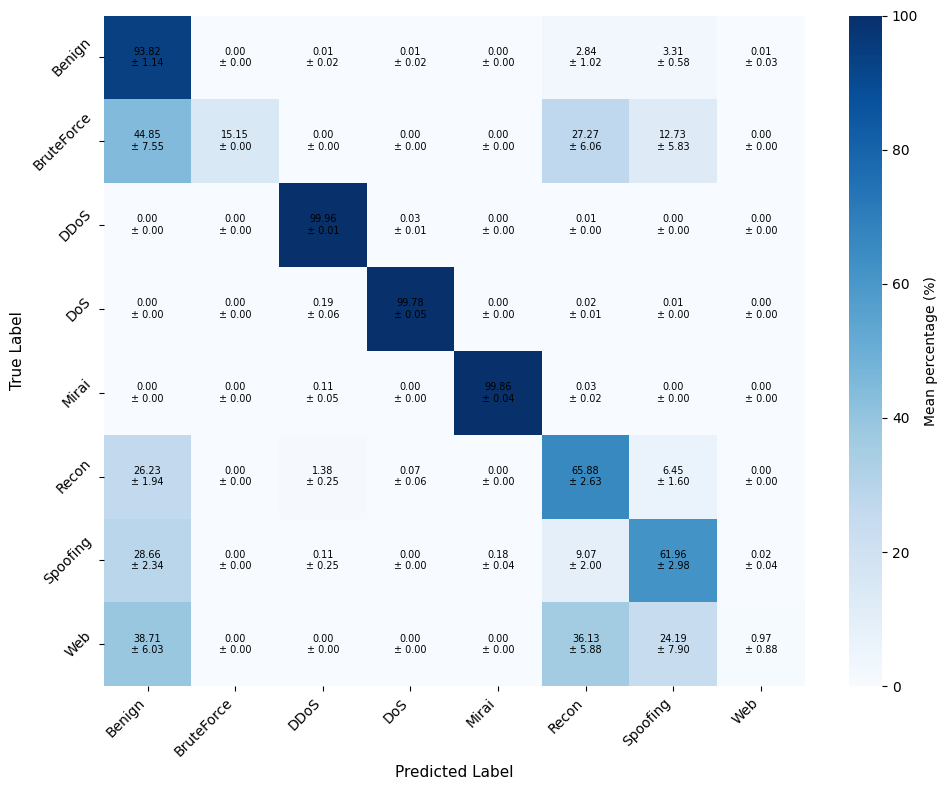

Saved the five-seed LSTM normalized confusion matrix mean ± sample SD.


In [21]:
# ============================================================
# Five-seed normalized confusion matrix: mean ± sample SD
# ============================================================
# One final figure is produced. Each seed is row-normalized
# first; then the cell-wise mean and sample SD are calculated
# across the five independent seed runs.

labels = np.arange(number_of_classes)
class_names = label_encoder.classes_

normalized_confusion_matrices = []

# Retrieve the stored predictions for all five LSTM seeds.
for candidate in representative_candidates_by_model["LSTM"]:

    seed_predictions = candidate["Predictions"]

    seed_cm = confusion_matrix(
        y_test,
        seed_predictions,
        labels=labels,
    )

    row_totals = seed_cm.sum(
        axis=1,
        keepdims=True,
    )

    seed_cm_normalized = np.divide(
        seed_cm,
        row_totals,
        out=np.zeros_like(
            seed_cm,
            dtype=float,
        ),
        where=row_totals != 0,
    )

    normalized_confusion_matrices.append(
        seed_cm_normalized
    )

normalized_confusion_matrices = np.stack(
    normalized_confusion_matrices,
    axis=0,
)

if normalized_confusion_matrices.shape[0] != len(RUN_SEEDS):
    raise ValueError(
        "The number of confusion matrices does not match "
        "the number of final-run seeds."
    )

mean_cm = np.mean(
    normalized_confusion_matrices,
    axis=0,
)

sd_cm = np.std(
    normalized_confusion_matrices,
    axis=0,
    ddof=1,
)

mean_cm_pct = mean_cm * 100.0
sd_cm_pct = sd_cm * 100.0

# Save numerical mean and SD matrices.
mean_cm_df = pd.DataFrame(
    mean_cm_pct,
    index=class_names,
    columns=class_names,
)

sd_cm_df = pd.DataFrame(
    sd_cm_pct,
    index=class_names,
    columns=class_names,
)

mean_cm_df.index.name = "True_Label"
mean_cm_df.columns.name = "Predicted_Label"
sd_cm_df.index.name = "True_Label"
sd_cm_df.columns.name = "Predicted_Label"

mean_cm_df.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "lstm_normalized_confusion_matrix_5_seed_mean.csv"
)

sd_cm_df.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "lstm_normalized_confusion_matrix_5_seed_sd.csv"
)

# Save a combined mean ± SD table.
mean_sd_table = pd.DataFrame(
    index=class_names,
    columns=class_names,
    dtype=object,
)

for i in range(number_of_classes):
    for j in range(number_of_classes):
        mean_sd_table.iloc[i, j] = (
            f"{mean_cm_pct[i, j]:.2f} "
            f"± {sd_cm_pct[i, j]:.2f}"
        )

mean_sd_table.index.name = "True_Label"
mean_sd_table.columns.name = "Predicted_Label"

mean_sd_table.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "lstm_normalized_confusion_matrix_5_seed_mean_sd.csv"
)

# Plot ONE final normalized mean ± SD confusion matrix.
plt.figure(
    figsize=(10, 8)
)

ax = sns.heatmap(
    mean_cm_pct,
    annot=False,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    vmin=0,
    vmax=100,
    cbar_kws={
        "label": "Mean percentage (%)"
    },
)

for i in range(number_of_classes):
    for j in range(number_of_classes):
        ax.text(
            j + 0.5,
            i + 0.5,
            (
                f"{mean_cm_pct[i, j]:.2f}"
                f"\n± {sd_cm_pct[i, j]:.2f}"
            ),
            ha="center",
            va="center",
            fontsize=7,
        )

plt.xlabel("Predicted Label", fontsize=11)
plt.ylabel("True Label", fontsize=11)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=45)
plt.tight_layout()

plt.savefig(
    REPORT_OUTPUT_DIRECTORY
    / "lstm_normalized_confusion_matrix_5_seed_mean_sd.pdf",
    bbox_inches="tight",
)

plt.savefig(
    REPORT_OUTPUT_DIRECTORY
    / "lstm_normalized_confusion_matrix_5_seed_mean_sd.png",
    dpi=600,
    bbox_inches="tight",
)

plt.show()

print(
    "Saved the five-seed LSTM normalized confusion matrix "
    "mean ± sample SD."
)


### Offline inference-time measurement


In [ ]:
# ============================================================
# Offline inference-time measurement using saved LSTM models
# ============================================================
# This cell can be run later without retraining the LSTM.
# It reloads the exact saved test tensor and each pretrained
# seed model, performs 3 warm-up predictions, and measures
# 5 full-test inference repetitions per model.

import time

OFFLINE_WARMUP_RUNS = 3
OFFLINE_TIMED_RUNS = 5

X_test_offline = np.load(
    REPORT_OUTPUT_DIRECTORY
    / "X_test_model_input.npy"
)

offline_timing_rows = []
offline_seed_summary_rows = []

for run_number, seed in enumerate(
    RUN_SEEDS,
    start=1,
):

    seed_output_directory = (
        REPORT_OUTPUT_DIRECTORY
        / f"LSTM_Seed_{run_number}"
    )

    model_path = (
        seed_output_directory
        / f"lstm_seed_{seed}.keras"
    )

    if not model_path.exists():
        raise FileNotFoundError(
            f"Saved LSTM model not found: {model_path}"
        )

    tf.keras.backend.clear_session()

    offline_model = tf.keras.models.load_model(
        model_path
    )

    warmup_size = min(
        1024,
        len(X_test_offline),
    )

    for _ in range(OFFLINE_WARMUP_RUNS):
        offline_model.predict(
            X_test_offline[:warmup_size],
            verbose=0,
        )

    seed_times = []

    for repetition in range(
        1,
        OFFLINE_TIMED_RUNS + 1,
    ):
        start_time = time.perf_counter()

        offline_model.predict(
            X_test_offline,
            verbose=0,
        )

        elapsed_time = (
            time.perf_counter()
            - start_time
        )

        seed_times.append(elapsed_time)

        offline_timing_rows.append(
            {
                "Run": run_number,
                "Seed": seed,
                "Repetition": repetition,
                "Inference_Time_s": elapsed_time,
                "Latency_ms_per_sample": (
                    elapsed_time
                    / len(X_test_offline)
                    * 1000.0
                ),
                "Throughput_samples_per_s": (
                    len(X_test_offline)
                    / elapsed_time
                ),
            }
        )

    seed_times = np.asarray(
        seed_times,
        dtype=float,
    )

    mean_time = float(seed_times.mean())
    sd_time = float(seed_times.std(ddof=1))

    offline_seed_summary_rows.append(
        {
            "Run": run_number,
            "Seed": seed,
            "Inference_Time_Mean_s": mean_time,
            "Inference_Time_SD_s": sd_time,
            "Latency_Mean_ms_per_sample": (
                mean_time
                / len(X_test_offline)
                * 1000.0
            ),
            "Latency_SD_ms_per_sample": (
                sd_time
                / len(X_test_offline)
                * 1000.0
            ),
            "Throughput_Mean_samples_per_s": (
                len(X_test_offline)
                / mean_time
            ),
        }
    )

    del offline_model
    tf.keras.backend.clear_session()
    gc.collect()

# Save all technical timing repetitions.
offline_timing_repetitions = pd.DataFrame(
    offline_timing_rows
)

offline_timing_repetitions.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "offline_inference_timing_repetitions.csv",
    index=False,
)

# Average repetitions within each independently trained seed.
offline_timing_per_seed = pd.DataFrame(
    offline_seed_summary_rows
)

offline_timing_per_seed.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "offline_inference_timing_per_seed.csv",
    index=False,
)

# Final five-seed summary: mean ± sample SD across the five
# independently trained models, not across all 25 repetitions.
offline_summary = pd.DataFrame(
    [
        {
            "N_Seeds": len(RUN_SEEDS),
            "Warmup_Runs_Per_Seed": OFFLINE_WARMUP_RUNS,
            "Timed_Runs_Per_Seed": OFFLINE_TIMED_RUNS,
            "Inference_Time_Mean_s": float(
                offline_timing_per_seed[
                    "Inference_Time_Mean_s"
                ].mean()
            ),
            "Inference_Time_SD_Across_Seeds_s": float(
                offline_timing_per_seed[
                    "Inference_Time_Mean_s"
                ].std(ddof=1)
            ),
            "Latency_Mean_ms_per_sample": float(
                offline_timing_per_seed[
                    "Latency_Mean_ms_per_sample"
                ].mean()
            ),
            "Latency_SD_Across_Seeds_ms_per_sample": float(
                offline_timing_per_seed[
                    "Latency_Mean_ms_per_sample"
                ].std(ddof=1)
            ),
            "Throughput_Mean_samples_per_s": float(
                offline_timing_per_seed[
                    "Throughput_Mean_samples_per_s"
                ].mean()
            ),
            "Throughput_SD_Across_Seeds_samples_per_s": float(
                offline_timing_per_seed[
                    "Throughput_Mean_samples_per_s"
                ].std(ddof=1)
            ),
        }
    ]
)

offline_summary.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "offline_inference_timing_summary.csv",
    index=False,
)

print("Offline inference timing completed.")
display(offline_timing_per_seed)
display(offline_summary)


### Representative LSTM confusion matrix

The representative run is the seed whose test macro F1 is closest to the
5-run LSTM mean. This follows the selection principle used in the original
five-run code.


In [22]:
representative_run_records = []


for model_name in ["LSTM"]:
    candidates = (
        representative_candidates_by_model[
            model_name
        ]
    )

    model_mean_f1 = float(
        all_run_results.loc[
            all_run_results[
                "Model"
            ] == model_name,
            "F1_macro",
        ].mean()
    )

    representative = min(
        candidates,
        key=lambda item: abs(
            item["F1_macro"]
            - model_mean_f1
        ),
    )

    representative_run_records.append(
        {
            "Model": model_name,
            "Representative_Run": (
                representative["Run"]
            ),
            "Representative_Seed": (
                representative["Seed"]
            ),
            "Representative_F1_macro": (
                representative[
                    "F1_macro"
                ]
            ),
            "Five_Run_Mean_F1_macro": (
                model_mean_f1
            ),
        }
    )

    output_stem = (
        REPORT_OUTPUT_DIRECTORY
        / (
            f"{model_name.lower()}_"
            "representative_confusion_matrix"
        )
    )

    plot_publication_confusion_matrix(
        y_test,
        representative[
            "Predictions"
        ],
        output_stem,
    )

    representative_report = (
        classification_report(
            y_test,
            representative[
                "Predictions"
            ],
            labels=np.arange(
                number_of_classes
            ),
            target_names=(
                label_encoder.classes_
            ),
            output_dict=True,
            zero_division=0,
        )
    )

    pd.DataFrame(
        representative_report
    ).transpose().to_csv(
        REPORT_OUTPUT_DIRECTORY
        / (
            f"{model_name.lower()}_"
            "representative_classification_report.csv"
        )
    )


# Keep the original result-variable name.
representative_runs = pd.DataFrame(
    representative_run_records
)

representative_runs.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "representative_runs.csv",
    index=False,
)


display(
    representative_runs
)

print(
    "All five-run LSTM outputs were saved to:"
)


,Model,Representative_Run,Representative_Seed,Representative_F1_macro,Five_Run_Mean_F1_macro
0,LSTM,4,45,0.6921,0.692007


All five-run LSTM outputs were saved to:


### Save Alloutputs


In [23]:
import shutil

# Compress the entire Kaggle working/output directory
shutil.make_archive(
    f"/kaggle/working/CICIoT2023_LSTM_{ABLATION_MODE}_5_Seed",
    "zip",
    "/kaggle/working"
)

print(
    f"Created: /kaggle/working/"
    f"CICIoT2023_LSTM_{ABLATION_MODE}_5_Seed.zip"
)


Created: /kaggle/working/CICIoT2023_LSTM_No_FA_5_Seed.zip
